<a class="anchor" id="0.1"></a>
# **Table of Contents**

- 1. [Setup](#1)
- 2. [Data Preparation](#2)
<!--     - 2.1 [Data Preparation for LSTM](#2.1) -->
- 3. [EDA](#3)
- 4. [Anomaly Detection](#4)
- 5. [Anomaly Creation](#5)
- 6. [Genetic Algoritm Otimization](#6)


# **1. SetUp** <a class="anchor" id="1"></a>

[Table of Contents](#0.1)

In [2]:
# Data Manipulation and Analysis
import numpy as np
import pandas as pd
from tqdm import tqdm 
import random

#Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Scikit-Learn for Machine Learning
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, confusion_matrix, ConfusionMatrixDisplay
from sklearn.metrics import precision_recall_curve


# Read a CSV file into a Pandas DataFrame
df = pd.read_csv("/kaggle/input/mobileum/jul_aug_sep_oct_2022_msc_1.csv", sep=";")

# Convert Start Date and Start Hour into a datetime object and set as index
df['TIMESTAMP'] = pd.to_datetime(df['Start Date'] + ' ' + df['Start Hour'].astype(str), format='%d/%m/%Y %H')
# df.set_index("TIMESTAMP", inplace=True)

# Clean the #Events column, remove any non-numeric characters, fill NaNs with 0, and convert to integer
df['#Events'] = df['#Events'].str.replace(r'[^\d.-]', '', regex=True)
df['#Events'] = df['#Events'].fillna(0)
df['#Events'] = pd.to_numeric(df['#Events']).astype(int)

# Drop unnecessary columns
# df.drop(columns=['Datasource', 'Start Date', 'Start Hour'], inplace=True) 
df.drop(columns=['Datasource', 'Start Date', 'Start Hour', 'Event Duration'], inplace=True)

# Drop duplicates
df.drop_duplicates(inplace=True)
# df=df.reset_index()

In [3]:
filters = pd.read_csv("/kaggle/input/mobileum-empty-agg/not_empty_combinations.csv")

In [4]:
def contain_condition(df, conditions):
    if not conditions:
        return False
    pd_conditions = " & ".join([f'`{key}` == "{value}"' for key, value in conditions.items()])
    return df.eval(pd_conditions).any()

# **4. Anomaly Creation** <a class="anchor" id="4"></a>

[Table of Contents](#0.1)

In [5]:
def filter_and_aggregate(df, filter_conditions, hierarchy=False):
    """
    Filters the DataFrame based on given conditions and aggregates by summing up a specified column.
    
    Args:
    - df: The original DataFrame.
    - filter_conditions: A dictionary where keys are column names and values are the values to filter on.
    
    Returns:
    - A new DataFrame with the filtered and aggregated data.
    """
    # Apply the filter conditions
    df_fil = df.copy()
    
    for col, val in filter_conditions.items():
        df_fil = df_fil[df_fil[col] == val]
    
    # Drop the columns used for filtering
    df_fil.drop(columns=list(filter_conditions.keys()), inplace=True)
    
    # Group by 'TIMESTAMP' and sum up the '#Events' column
    if hierarchy:
        df_agg = df_fil.groupby('TIMESTAMP')[['#Events','Anomaly']].sum().reset_index()
    else:
        df_agg = df_fil.groupby('TIMESTAMP')['#Events'].sum().reset_index()
    
    return df_agg

### Random select one anomaly from generated anomalies

In [6]:
ncats = {}
for column in ['Call Type', 'Event Type', 'Subscriber Type', 'Traffic Type', 'Service Type', 'Partner Description']:
    ncats[column] = len(df[column].unique())
ncats

# Function to aggregate while preserving single unique values
def agg_preserve_singles(x):
    if x.nunique() == 1:
        return x.iloc[0]  # Return the single unique value
    elif x.nunique() == ncats[x.name]:
        return 'All'
    else:
        return x.nunique()  # Return number of unique values

# Apply the function to each column in the grouped dataframe
anomalies = df_anomaly[df_anomaly['Anomaly']!=0].groupby("TIMESTAMP").agg(
    lambda x: agg_preserve_singles(x) if x.name != '#Events' else x.sum()
)

len(anomalies)

NameError: name 'df_anomaly' is not defined

In [ ]:
anomalies.iloc[:30]

In [7]:
df_anomaly = pd.read_csv("/kaggle/input/mobileum/df_anomaly.csv")

In [ ]:
df_anomaly[df_anomaly.TIMESTAMP == "2022-08-07 19:00:00"][df_anomaly.Anomaly == 1]

In [ ]:
center_ts = "2022-08-07 19:00:00"
conditions = {'Call Type':'VOICE', 'Event Type':'CALL FORWARD', 'Subscriber Type':'Prepaid'
             ,'Service Type':'NOT-ROAMING'}
static_value = list(conditions.values())[0]
column = list(conditions.keys())[0]
index = 217865
print(f" INDEX = {index} \n timestamp Selected: {center_ts} \n Conditions: {conditions} \n FIX filter: {static_value} => {column}")

In [ ]:
filters

In [ ]:
## Reducing the redundancy to with number of rows equals 2110
filters_fil =filters[(filters[column]==static_value) &(filters["Number of examples (rows)"]==2110)]

## Remove all columns with unique values
rm_columns = list(filters_fil.columns[filters_fil.nunique() == 1])

new_filters = filters_fil.drop(rm_columns, axis = 1)
index = np.random.choice(len(new_filters)-1)
plot_filters = new_filters.iloc[index].values
print(f"Df after filtering {column} => {static_value} : \n{filters_fil}")
print(f"After removing all columns with unique values: \n{new_filters}")
print(f"Columns with unique values: {rm_columns}")
print(f"New filters to use in plot: {plot_filters}")

In [ ]:
index

In [ ]:
df_anomaly_filters = df_anomaly[(df_anomaly["TIMESTAMP"]==center_ts) & (df_anomaly[column]==static_value)]
rm_columns = list(df_anomaly_filters.columns[df_anomaly_filters.nunique() == 1])
df_anomaly_new_filters = df_anomaly_filters.drop(rm_columns, axis=1)

### Desagreggated dataframe from aggregation and Possible aggreation after filters with 2110 rows (which include all timestamps) 

In [8]:
import matplotlib.pyplot as plt

def plot_figure(df_anomaly, df_original, center_ts, conditions, title_add, mp_value):

    # Ensure datetime in columns
    df_anomaly["TIMESTAMP"] = pd.to_datetime(df_anomaly["TIMESTAMP"])
    df_original["TIMESTAMP"] = pd.to_datetime(df_original["TIMESTAMP"])

    # Ensure center timestamp is also datetime
    center_ts = pd.to_datetime(center_ts)

    # Reset index correctly
    df_anomaly = df_anomaly.reset_index(drop=True)
    df_original = df_original.reset_index(drop=True)
    #Obter o maximo da coluna #Events de df_original e de df_anomaly e df original para escalar o mp_value e depois fazer o plot do mesmo
    
    
    # Find index of center timestamp
    center_index = df_anomaly.index[df_anomaly["TIMESTAMP"] == center_ts][0]

    low = max(center_index - 25, 0)
    high = min(center_index + 25, len(df_anomaly))

    plot_df_anomaly = df_anomaly.iloc[low:high]
    plot_df_original = df_original.iloc[low:high]

    fig, ax = plt.subplots(figsize=(12, 6))

    ax.plot(plot_df_original["TIMESTAMP"], plot_df_original["#Events"], label="Original", marker="o")
    ax.plot(plot_df_anomaly["TIMESTAMP"], plot_df_anomaly["#Events"], label="Anomaly", marker="x")

    # Highlight center point
    ax.scatter(
        center_ts,
        df_anomaly.loc[center_index, "#Events"],
        edgecolors="red",
        facecolors="none",
        s=800,
        linewidths=8,
        label="Used Anomaly"
    )

    ax.set_title(f"{title_add}: {', '.join(map(str, conditions.values()))}")
    ax.set_xlabel("Timestamp")
    ax.set_ylabel("#Eventos")
    ax.legend()
    ax.grid(True)
    plt.tight_layout()
    plt.show()


In [9]:
mp_values[1]

NameError: name 'mp_values' is not defined

In [16]:
import numpy as np
import stumpy
import matplotlib.pyplot as plt
import pandas as pd
import os

def plot_figure(df_anomaly, df_original, center_ts, conditions, title_add, mp_values, save_dir):

    # Ensure save directory exists
    os.makedirs(save_dir, exist_ok=True)

    # -----------------------------
    # 1. Preparação dos dados
    # -----------------------------
    df_anomaly["TIMESTAMP"] = pd.to_datetime(df_anomaly["TIMESTAMP"])
    df_original["TIMESTAMP"] = pd.to_datetime(df_original["TIMESTAMP"])
    center_ts = pd.to_datetime(center_ts)

    df_anomaly = df_anomaly.reset_index(drop=True)
    df_original = df_original.reset_index(drop=True)

    # -----------------------------
    # 2. Window around center
    # -----------------------------
    center_index = df_anomaly.index[df_anomaly["TIMESTAMP"] == center_ts][0]
    low = max(center_index - 25, 0)
    high = min(center_index + 25, len(df_anomaly))

    plot_df_anomaly = df_anomaly.iloc[low:high]
    plot_df_original = df_original.iloc[low:high]

    # -----------------------------
    # 3. Align MP values to window
    # -----------------------------
    mp_values_window = mp_values[low:high]
    if len(mp_values_window) < len(plot_df_original):
        mp_values_window = np.pad(mp_values_window, 
                                  (0, len(plot_df_original) - len(mp_values_window)), 
                                  'edge')

    global_max = max(df_original["#Events"].max(), df_anomaly["#Events"].max())
    mp_scaled = mp_values_window * global_max

    # -----------------------------
    # 4. Plot
    # -----------------------------
    fig, ax = plt.subplots(figsize=(12, 6))

    ax.plot(plot_df_original["TIMESTAMP"], plot_df_original["#Events"], label="Original", marker="o")
    ax.plot(plot_df_anomaly["TIMESTAMP"], plot_df_anomaly["#Events"], label="Anomaly", marker="x")

    ax.scatter(center_ts, df_anomaly.loc[center_index, "#Events"], edgecolors="red",
               facecolors="none", s=800, linewidths=8, label="Used Anomaly")

    ax.plot(plot_df_original["TIMESTAMP"], mp_scaled, linestyle="--", linewidth=2, label="MP scaled")

    ax.set_title(f"{title_add}: {', '.join(map(str, conditions.values()))}")
    ax.set_xlabel("Timestamp")
    ax.set_ylabel("#Eventos")
    ax.legend()
    ax.grid(True)
    plt.tight_layout()

    # -----------------------------
    # 5. Save figure as PNG
    # -----------------------------
    # # Create a safe filename from title and conditions
    # cond_str = "_".join([f"{k}-{v}" for k, v in conditions.items()]) if conditions else "all"
    # filename = f"{title_add.strip().replace(' ', '_')}_{cond_str}.png"
    # filepath = os.path.join(save_dir, filename)
    # plt.savefig(filepath, dpi=300)
    # plt.close(fig)  # Close the figure to free memory
    # print(f"Saved plot to {filepath}")


In [17]:
df_original_agg = filter_and_aggregate(df, {}, False)
df_original_cond = filter_and_aggregate(df, conditions, False)

df_anomaly_agg = filter_and_aggregate(df_anomaly, {}, False)
df_anomaly_cond = filter_and_aggregate(df_anomaly, conditions, False)

NameError: name 'conditions' is not defined

In [ ]:
df_anomaly_agg[df_anomaly_agg.TIMESTAMP == center_ts]

In [ ]:
center_ts

In [19]:
import stumpy
center_ts = "2022-08-07 12:00:00"

2110
2110
1


ValueError: The window size must be less than or equal to 1

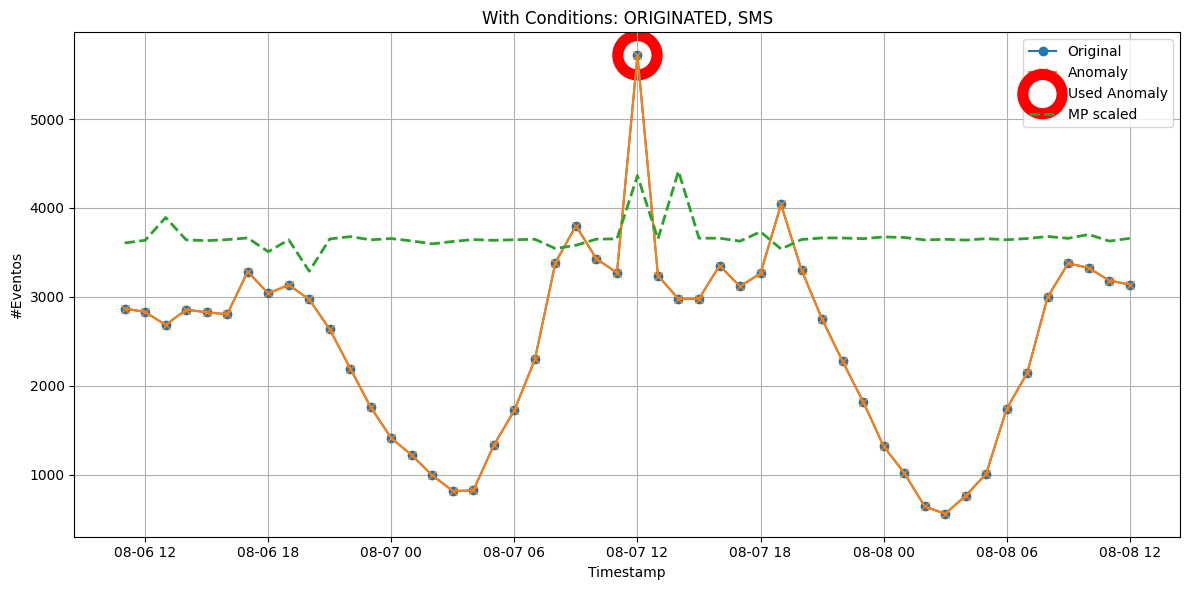

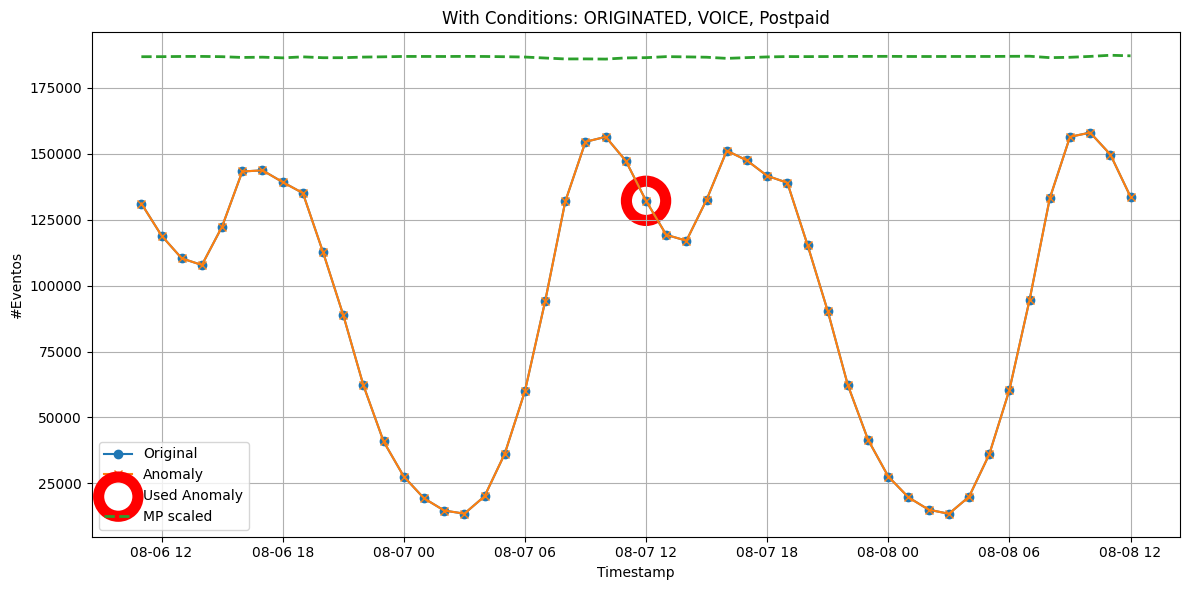

In [27]:
def get_mp_values(df):
    # Extract time series and check length
    ts = df["#Events"].to_numpy().astype(float)


    # Calculate Matrix Profile

    matrix_profile = stumpy.stump(ts, m=168, ignore_trivial=True)
    mp_values = matrix_profile[:, 0]  # Extract Matrix Profile values
    mp_values = np.diff(mp_values)  # Calculate differences of Matrix Profile

    # Normalize Matrix Profile values to [0, 1]
    mp_min, mp_max = np.min(mp_values), np.max(mp_values)
    if mp_max == mp_min:
        mp_values_normalized = np.zeros_like(mp_values)
    else:
        mp_values_normalized = (mp_values - mp_min) / (mp_max - mp_min)
    return mp_values_normalized

dictionary_list = [
    {'Event Type': 'ORIGINATED', 'Call Type': 'SMS'},
    {'Event Type': 'ORIGINATED', 'Call Type': 'VOICE', 'Subscriber Type': 'Postpaid'},
    {'Event Type': 'ORIGINATED', 'Call Type': 'VOICE', 'Subscriber Type': 'Application', 'Traffic Type': 'OFF-NET'},
    {'Event Type': 'ORIGINATED', 'Call Type': 'VOICE', 'Subscriber Type': 'Application', 'Traffic Type': 'INT'},
    {'Event Type': 'ORIGINATED', 'Call Type': 'VOICE', 'Subscriber Type': 'Application', 'Traffic Type': 'ON-NET'},
    {'Event Type': 'ORIGINATED', 'Call Type': 'VOICE', 'Subscriber Type': 'Roamer In', 'Service Type': 'NOT-ROAMING'},
    {'Event Type': 'ORIGINATED', 'Call Type': 'VOICE', 'Subscriber Type': 'Roamer In', 'Service Type': 'ROAMING'},
    {'Event Type': 'ORIGINATED', 'Call Type': 'VOICE', 'Subscriber Type': 'Prepaid'},
    {'Event Type': 'ORIGINATED', 'Call Type': 'VOICE', 'Subscriber Type': 'Other', 'Traffic Type': 'OFF-NET'},
    {'Event Type': 'ORIGINATED', 'Call Type': 'VOICE', 'Subscriber Type': 'Other', 'Traffic Type': 'INT'},
    {'Event Type': 'ORIGINATED', 'Call Type': 'VOICE', 'Subscriber Type': 'Other', 'Traffic Type': 'ON-NET'},
    {'Event Type': 'CALL FORWARD', 'Subscriber Type': 'Postpaid'},
    {'Event Type': 'CALL FORWARD', 'Subscriber Type': 'Application'},
    {'Event Type': 'CALL FORWARD', 'Subscriber Type': 'Roamer In', 'Call Type': 'SMS'},
    {'Event Type': 'CALL FORWARD', 'Subscriber Type': 'Roamer In', 'Call Type': 'VOICE'},
    {'Event Type': 'CALL FORWARD', 'Subscriber Type': 'Prepaid'},
    {'Event Type': 'CALL FORWARD', 'Subscriber Type': 'Other', 'Service Type': 'NOT-ROAMING'},
    {'Event Type': 'CALL FORWARD', 'Subscriber Type': 'Other', 'Service Type': 'ROAMING'},
    {'Event Type': 'TERMINATED', 'Call Type': 'SMS', 'Traffic Type': 'OFF-NET'},
    {'Event Type': 'TERMINATED', 'Call Type': 'SMS', 'Traffic Type': 'INT'},
    {'Event Type': 'TERMINATED', 'Call Type': 'SMS', 'Traffic Type': 'ON-NET'},
    {'Event Type': 'TERMINATED', 'Call Type': 'VOICE', 'Service Type': 'NOT-ROAMING', 'Subscriber Type': 'Postpaid'},
    {'Event Type': 'TERMINATED', 'Call Type': 'VOICE', 'Service Type': 'NOT-ROAMING', 'Subscriber Type': 'Application'},
    {'Event Type': 'TERMINATED', 'Call Type': 'VOICE', 'Service Type': 'NOT-ROAMING', 'Subscriber Type': 'Roamer In'},
    {'Event Type': 'TERMINATED', 'Call Type': 'VOICE', 'Service Type': 'NOT-ROAMING', 'Subscriber Type': 'Prepaid'},
    {'Event Type': 'TERMINATED', 'Call Type': 'VOICE', 'Service Type': 'NOT-ROAMING', 'Subscriber Type': 'Other'},
    {'Event Type': 'TERMINATED', 'Call Type': 'VOICE', 'Service Type': 'ROAMING'},
    {'Event Type': 'ROAMING OUT', 'Traffic Type': 'OFF-NET', 'Subscriber Type': 'Postpaid'},
    {'Event Type': 'ROAMING OUT', 'Traffic Type': 'OFF-NET', 'Subscriber Type': 'Application'},
    {'Event Type': 'ROAMING OUT', 'Traffic Type': 'OFF-NET', 'Subscriber Type': 'Roamer In'},
    {'Event Type': 'ROAMING OUT', 'Traffic Type': 'OFF-NET', 'Subscriber Type': 'Prepaid', 'Service Type': 'NOT-ROAMING'},
    {'Event Type': 'ROAMING OUT', 'Traffic Type': 'OFF-NET', 'Subscriber Type': 'Prepaid', 'Service Type': 'ROAMING'},
    {'Event Type': 'ROAMING OUT', 'Traffic Type': 'OFF-NET', 'Subscriber Type': 'Other'},
    {'Event Type': 'ROAMING OUT', 'Traffic Type': 'INT', 'Subscriber Type': 'Postpaid'},
    {'Event Type': 'ROAMING OUT', 'Traffic Type': 'INT', 'Subscriber Type': 'Application'},
    {'Event Type': 'ROAMING OUT', 'Traffic Type': 'INT', 'Subscriber Type': 'Roamer In'},
    {'Event Type': 'ROAMING OUT', 'Traffic Type': 'INT', 'Subscriber Type': 'Prepaid'},
    {'Event Type': 'ROAMING OUT', 'Traffic Type': 'INT', 'Subscriber Type': 'Other'},
    {'Event Type': 'ROAMING OUT', 'Traffic Type': 'ON-NET', 'Subscriber Type': 'Postpaid'},
    {'Event Type': 'ROAMING OUT', 'Traffic Type': 'ON-NET', 'Subscriber Type': 'Application'},
    {'Event Type': 'ROAMING OUT', 'Traffic Type': 'ON-NET', 'Subscriber Type': 'Roamer In'},
    {'Event Type': 'ROAMING OUT', 'Traffic Type': 'ON-NET', 'Subscriber Type': 'Prepaid'},
    {'Event Type': 'ROAMING OUT', 'Traffic Type': 'ON-NET', 'Subscriber Type': 'Other'}
]



for dictionary in dictionary_list:
    df_original_cond = filter_and_aggregate(df_anomaly, dictionary, False)
    print(len(df_original_cond))
    # if(df_original_cond==2110):
    mp_values = get_mp_values(df_original_cond)
    df_anomaly_cond = filter_and_aggregate(df_anomaly, dictionary, False)
    plot_figure(df_anomaly_cond, df_original_cond, center_ts, dictionary, "With Conditions", mp_values, "/kaggle/working/")


In [ ]:
df_original_cond

In [ ]:
available_categories = {
    'Call Type': df['Call Type'].unique().tolist(),
    'Event Type': df['Event Type'].unique().tolist(),
    'Subscriber Type': df['Subscriber Type'].unique().tolist(),
    'Traffic Type': df['Traffic Type'].unique().tolist(),
    'Service Type': df['Service Type'].unique().tolist(),
    'Partner Description': df['Partner Description'].unique().tolist(),
    'STOP': False
}


def revert_key_value_mapping(available_categories):
    reversed_mapping = {}
    for key, values in available_categories.items():
        if isinstance(values, list):  # Ensure the value is iterable
            for value in values:
                if value not in reversed_mapping:
                    reversed_mapping[value] = []
                reversed_mapping[value].append(key)
        else:
            # Handle non-list values (like the 'STOP' flag)
            value = values
            if value not in reversed_mapping:
                reversed_mapping[value] = []
            reversed_mapping[value].append(key)
    return reversed_mapping

In [ ]:
rt_available_categories = revert_key_value_mapping(available_categories)

In [ ]:
static_value

In [ ]:
column:static_value

In [ ]:
dictionary = {column:static_value}
df_original_cond = filter_and_aggregate(df, dictionary, False)
df_anomaly_cond = filter_and_aggregate(df_anomaly, dictionary, False)
plot_figure(df_anomaly_cond, df_original_cond, center_ts, dictionary, "WithConditions: ")

In [ ]:
dictionary_list = [
    {},
    {'Call Type': 'VOICE', 'Event Type': 'CALL FORWARD', 'Subscriber Type': 'Prepaid', 'Service Type': 'NOT-ROAMING'},
    {'Call Type': 'VOICE', 'Event Type': 'CALL FORWARD'},
    {'Call Type': 'VOICE', 'Event Type': 'CALL FORWARD', 'Traffic Type':'INT'},
    {'Call Type': 'VOICE', 'Event Type': 'CALL FORWARD','Subscriber Type':'Postpaid'}
]

In [ ]:
df_original_cond

In [ ]:
for dictionary in dictionary_list:
    df_original_cond = filter_and_aggregate(df, dictionary, False)
    df_anomaly_cond = filter_and_aggregate(df_anomaly, dictionary, False)
    plot_figure(df_anomaly_cond, df_original_cond, center_ts, dictionary, "WithConditions: ")

In [ ]:
import itertools


def create_dictionaries(static_filter, filters, category_dict):
    all_combinations = []
    for r in range(1, len(filters) + 1):
        for combination in itertools.combinations(filters, r):
            current_dict = {}
            
            current_dict[static_filter[0]] = static_filter[1]
            for item in combination:
                category = category_dict.get(item)[0]
                
                if category:
                    # Assigning the filter to the correct category in the dictionary
                    
                    current_dict[category] = item
            if current_dict:  # Make sure the dictionary is not empty
                all_combinations.append(current_dict)
    return all_combinations

# Generating dictionaries
static_filter = [column, static_value]
resulting_dictionaries = create_dictionaries(static_filter, plot_filters, rt_available_categories)


# Print each generated dictionary
for dictionary in resulting_dictionaries:
    df_original_cond = filter_and_aggregate(df, dictionary, False)
    df_anomaly_cond = filter_and_aggregate(df_anomaly, dictionary, False)
    plot_figure(df_anomaly_cond, df_original_cond, center_ts, dictionary, "WithConditions: ")